# 13 · Catalyst deactivation and reactor operation

Catalysts lose activity by sintering, coking and poisoning, and a reactor designed for fresh catalyst falls
short within days. This notebook models the decay laws and their mechanisms, follows a packed bed as its
catalyst dies (the conversion falls, then the temperature is raised to compensate), sizes the catalyst
inventory for a cycle, and looks at the moving-bed and fluidised-bed designs that handle catalysts too
short-lived for fixed beds.

**What you will learn**
- fit decay laws and relate them to mechanisms
- predict the conversion of a bed as its catalyst deactivates
- size catalyst inventory for a cycle and plan a temperature schedule
- choose between fixed, moving and fluidised beds

**Before you start:** notebook 10  ·  **Time:** about 60 min

In [1]:
try:                      # on Google Colab (or anywhere engreact is missing): install it from GitHub
    import engreact
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engreact"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engreact import catalysis, datasets, kinetics
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Decay laws and mechanisms

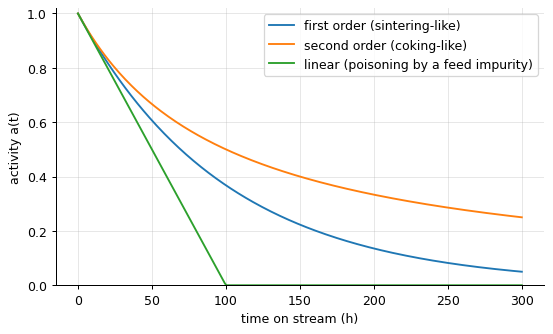

the course data: second-order decay with k_d = 0.0121 1/h -> activity 0.5 after 82 h, 0.2 after 330 h


In [2]:
t = np.linspace(0, 300, 300)
fig, ax = plt.subplots()
for law, lbl in (("first", "first order (sintering-like)"), ("second", "second order (coking-like)"), ("linear", "linear (poisoning by a feed impurity)")):
    ax.plot(t, catalysis.activity(t, 0.01, law), label=lbl)
ax.set(xlabel="time on stream (h)", ylabel="activity a(t)", ylim=(0, 1.02)); ax.legend(); plt.show()
d = pd.read_csv(datasets.path("catalyst_deactivation.csv"), comment="#")
fit = catalysis.fit_deactivation(d.t_h, d.activity, "second")
print(f"the course data: second-order decay with k_d = {fit['k_d']:.4f} 1/h -> activity 0.5 after {1/fit['k_d']:.0f} h, 0.2 after {4/fit['k_d']:.0f} h")

The three laws have different tails: first-order decay is exponential, second-order slows itself (the
remaining activity decays more slowly as coke covers the surface), linear poisoning marches to zero. The
fitted second-order constant gives the cycle length directly - and for a coking catalyst the cycle ends with
a regeneration by burning the coke off.

## A packed bed with a dying catalyst

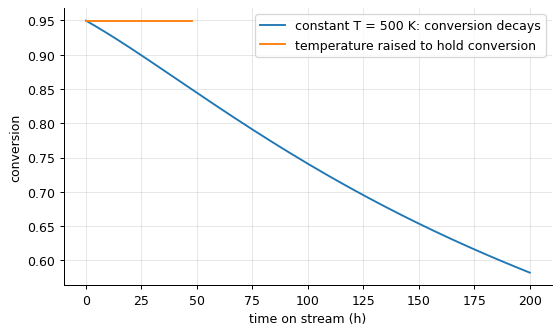

holding conversion needs the temperature to reach 545 K after 48 h; raising T also accelerates the decay (its own activation energy) - the climb steepens


In [3]:
k0, Ea = 1e8, 50e3
W_over_F = 5.0                                                       # kg s/mol, the bed's catalyst-to-feed ratio... in "tau" units k' W/F
def conversion(T, a):
    return 1 - np.exp(-kinetics.arrhenius(k0, Ea, T) * a * W_over_F * 1e-3)   # first order, per kg of catalyst
hours = np.linspace(0, 200, 201)
a = catalysis.activity(hours, fit["k_d"], "second")
fig, ax = plt.subplots()
ax.plot(hours, conversion(500.0, a), label="constant T = 500 K: conversion decays")
traj = catalysis.temperature_time_trajectory(k_d0=fit["k_d"] / 3600 / np.exp(-60e3 / (8.314 * 500.0)), E_d=60e3, k0=k0, Ea=Ea, T0=500.0, t_max=200 * 3600, T_max=545.0)
ax.plot(traj["t"] / 3600, [conversion(T_, a_) for T_, a_ in zip(traj["T"], traj["a"])], label="temperature raised to hold conversion")
ax.set(xlabel="time on stream (h)", ylabel="conversion"); ax.legend(); plt.show()
print(f"holding conversion needs the temperature to reach 545 K after {traj['t'][-1]/3600:.0f} h; raising T also accelerates the decay (its own activation energy) - the climb steepens")

At constant temperature the conversion of a first-order reaction sags as the activity does. Raising the
temperature restores it - until the maximum allowable temperature, and with an accelerating climb because
the deactivation reaction is itself thermally activated. Reformers, hydrotreaters and ammonia converters run
this schedule over months; the end-of-run temperature defines the cycle.

## Sizing the catalyst inventory for a cycle

In [4]:
target, cycle_h = 0.9, 720.0                                        # 90 % conversion for a 30-day cycle at constant T
a_end = catalysis.activity(cycle_h, fit["k_d"], "second")
k500 = kinetics.arrhenius(k0, Ea, 500.0)
W_over_F_needed = -np.log(1 - target) / (k500 * a_end * 1e-3)
W_over_F_fresh = -np.log(1 - target) / (k500 * 1e-3)
print(f"activity at the end of the cycle: {a_end:.3f}; catalyst needed: {W_over_F_needed:.1f} kg s/mol against {W_over_F_fresh:.1f} for fresh catalyst - {W_over_F_needed/W_over_F_fresh:.1f} x")

activity at the end of the cycle: 0.103; catalyst needed: 37.5 kg s/mol against 3.9 for fresh catalyst - 9.7 x


A bed sized for fresh catalyst meets specification on day one and fails by the end of the month. Sizing for
the end-of-cycle activity means installing several times the "kinetic" inventory - the true cost of
deactivation, and the incentive for the alternatives below.

## Moving beds and fluidised beds

In [5]:
# moving bed: catalyst and gas flow together (co-current); the activity at the outlet is a(t_residence)
U_s = np.array([0.5, 1.0, 2.0, 5.0])                                 # catalyst mass flow (kg/h) through a 100 kg bed
for u in U_s:
    t_res = 100.0 / u
    a_out = catalysis.activity(t_res, fit["k_d"], "second")
    a_mean = np.mean(catalysis.activity(np.linspace(0, t_res, 200), fit["k_d"], "second"))
    print(f"catalyst flow {u:4.1f} kg/h: residence {t_res:6.0f} h, outlet activity {a_out:.3f}, mean activity in the bed {a_mean:.3f}")
print("\nfluidised bed with continuous regeneration: the catalyst is well mixed, so its activity is a single steady value set by the regeneration rate (FCC: minutes of residence, coke burned off in the regenerator)")

catalyst flow  0.5 kg/h: residence    200 h, outlet activity 0.292, mean activity in the bed 0.508
catalyst flow  1.0 kg/h: residence    100 h, outlet activity 0.452, mean activity in the bed 0.655
catalyst flow  2.0 kg/h: residence     50 h, outlet activity 0.622, mean activity in the bed 0.782
catalyst flow  5.0 kg/h: residence     20 h, outlet activity 0.805, mean activity in the bed 0.895

fluidised bed with continuous regeneration: the catalyst is well mixed, so its activity is a single steady value set by the regeneration rate (FCC: minutes of residence, coke burned off in the regenerator)


When the catalyst dies in hours rather than months, the fixed bed gives way to a moving bed (catalyst
slowly circulated and regenerated, as in continuous catalytic reforming) or a fluidised bed with a
regenerator (fluid catalytic cracking, where the catalyst lives for seconds between regenerations). The
choice of reactor follows from the deactivation time scale - one more reason to measure it early.

## Inside the algorithm: second-order decay

In [6]:
t_ = 100.0
print("by hand: a =", 1 / (1 + fit["k_d"] * t_), "; library:", float(catalysis.activity(t_, fit["k_d"], "second")))

by hand: a = 0.45178542658368276 ; library: 0.45178542658368276


## Exercises
1. Regeneration takes 24 h and restores full activity. For a bed at constant 500 K, find the cycle length that maximises the time-averaged conversion (production during the cycle divided by cycle + regeneration time).
2. Poisoning by a feed impurity gives linear decay with k_d proportional to the impurity concentration. If a guard bed removes 90 % of the impurity, how much longer is the cycle? Compare with the cost of 10 x more catalyst.
3. **Implement it yourself:** integrate the activity ODE da/dt = -k_d(T) a^2 along the library's temperature-time trajectory and confirm that the product k(T) a stays constant.